In [2]:
# Import required libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

# Display all columns
pd.set_option('display.max_columns', None)

# Display numbers with 2 decimal places
pd.set_option('display.float_format', '{:.2f}'.format)

In [3]:
# import the data

df = pd.read_csv("../dataset/WA_Fn-UseC_-Telco-Customer-Churn.csv")
df.head(5)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.shape

(7043, 21)

In [5]:
# health check for your dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


"Why is a numerical column stored as an object?"

A good answer would be:

"Because the column contains non-numeric values such as blank strings or other text. Pandas therefore infers the entire column as object. We need to identify those values, handle them appropriately, and then convert the column to a numeric type."

In [6]:
# summarizes numeric columns
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.00,7043.00,7043.00
mean,0.16,32.37,64.76
std,0.37,24.56,30.09
min,0.00,0.00,18.25
25%,0.00,9.00,35.50
50%,0.00,29.00,70.35
75%,0.00,55.00,89.85
max,1.00,72.00,118.75


In [7]:
# summarize non-numeric columns
df.describe(include=object)

,customerID,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,TotalCharges,Churn
count,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043
unique,7043,2,2,2,2,3,3,3,3,3,3,3,3,3,2,4,6531,2
top,7590-VHVEG,Male,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,,No
freq,1,3555,3641,4933,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,11,5174


In [8]:

# Check missing values

df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [9]:
# Check unique values in TotalCharges

df["TotalCharges"].unique()

array(['29.85', '1889.5', '108.15', ..., '346.45', '306.6', '6844.5'],
      dtype=object)

In [10]:
# count of null values

(df["TotalCharges"] == " ").sum()

11

In [11]:
df[df["TotalCharges"] == " "]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,No,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,Yes,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,Yes,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,Yes,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


In [12]:
# Convert TotalCharges to numeric 
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

What does errors="coerce" mean?

It tells pandas:

"If you find a value that cannot be converted to a number, don't crash. Instead, replace it with NaN."

In [13]:
# verify
df["TotalCharges"].isnull().sum()

11

In [14]:
# Percentage of missing values in TotalCharges

(df["TotalCharges"].isnull().sum() / len(df)) * 100

0.1561834445548772

In [16]:
# Remove rows where TotalCharges is missing
df.dropna(subset =['TotalCharges'],inplace = True)

In [17]:
df

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.50,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.90,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.60,Yes


#### Verifying after dropping

In [18]:
df.shape

(7032, 21)

In [19]:
df["TotalCharges"].isnull().sum()

0

In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 7032 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7032 non-null   object 
 1   gender            7032 non-null   object 
 2   SeniorCitizen     7032 non-null   int64  
 3   Partner           7032 non-null   object 
 4   Dependents        7032 non-null   object 
 5   tenure            7032 non-null   int64  
 6   PhoneService      7032 non-null   object 
 7   MultipleLines     7032 non-null   object 
 8   InternetService   7032 non-null   object 
 9   OnlineSecurity    7032 non-null   object 
 10  OnlineBackup      7032 non-null   object 
 11  DeviceProtection  7032 non-null   object 
 12  TechSupport       7032 non-null   object 
 13  StreamingTV       7032 non-null   object 
 14  StreamingMovies   7032 non-null   object 
 15  Contract          7032 non-null   object 
 16  PaperlessBilling  7032 non-null   object 


Why did you remove those 11 rows instead of filling them with 0?

"After converting TotalCharges to numeric, I found only 11 missing values out of 7,043 records (around 0.16%). Since the proportion was very small, removing those rows had negligible impact on the dataset. Additionally, those customers had tenure = 0, meaning they were brand-new customers with no billing history. Dropping them simplified preprocessing without introducing assumptions into the data."

## EDA

In [22]:
# Count the values in the target column

df["Churn"].value_counts()

No     5163
Yes    1869
Name: Churn, dtype: int64

In [23]:
# Percentage distribution of the target variable

df["Churn"].value_counts(normalize=True) * 100

No    73.42
Yes   26.58
Name: Churn, dtype: float64

50% vs 50% → Balanced , 
95% vs 5% → Highly imbalanced ,
73% vs 27% → Moderately imbalanced

##### Observation
Is your dataset balanced?

"No. The target variable is moderately imbalanced, with approximately 73% non-churn customers and 27% churn customers. It's not severe enough to require techniques like SMOTE immediately, but accuracy alone would be misleading, so I'd evaluate the model using Precision, Recall, F1-score, and ROC-AUC."

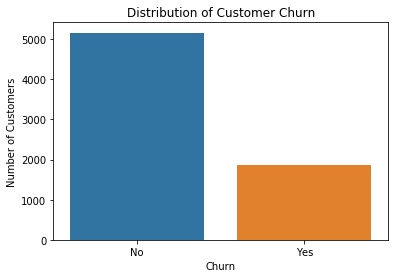

In [25]:
# Visualize the target variable

plt.figure(figsize=(6,4))
sns.countplot(data=df, x= "Churn")
plt.title("Distribution of Customer Churn")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

### Categorical Features

In [26]:
# analyzing gender

# Count of each gender

df["gender"].value_counts()

Male      3549
Female    3483
Name: gender, dtype: int64

In [27]:
# Percentage distribution

df["gender"].value_counts(normalize=True) * 100

Male     50.47
Female   49.53
Name: gender, dtype: float64

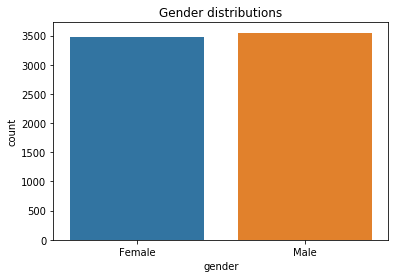

In [29]:
plt.figure(figsize=(6,4))
sns.countplot(data=df, x="gender")
plt.title('Gender distributions')
plt.show()

In [30]:
# gender with churn 

pd.crosstab(df["gender"], df["Churn"])

Churn,No,Yes
gender,,
Female,2544,939
Male,2619,930


In [32]:
pd.crosstab(
    df["gender"],
    df["Churn"],
    normalize="index"
) * 100

Churn,No,Yes
gender,,
Female,73.04,26.96
Male,73.80,26.20


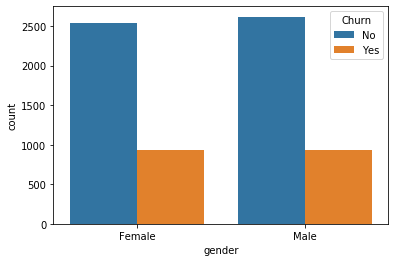

In [31]:
sns.countplot(
    data=df,
    x="gender",
    hue="Churn"
)

#### Business Interpretation

If a telecom company asked:

"Should we create different retention campaigns for men and women?"

Probably not. The churn rates are almost identical, so gender alone does not appear to be a strong driver of customer churn.

"The dataset is balanced with approximately 51% males and 49% females. During bivariate analysis, both genders showed very similar churn rates (around 27%), suggesting that gender is not a strong predictor of churn on its own."

In [33]:
# analyzing SeniorCitizen

# univariate

df["SeniorCitizen"].value_counts()



0    5890
1    1142
Name: SeniorCitizen, dtype: int64

In [34]:
df["SeniorCitizen"].value_counts(normalize=True) * 100

0   83.76
1   16.24
Name: SeniorCitizen, dtype: float64

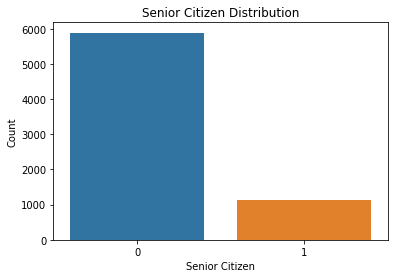

In [35]:
plt.figure(figsize=(6,4))

sns.countplot(data=df, x="SeniorCitizen")

plt.title("Senior Citizen Distribution")
plt.xlabel("Senior Citizen")
plt.ylabel("Count")

plt.show()

In [36]:

# bivariate

pd.crosstab(df["SeniorCitizen"], df["Churn"])

Churn,No,Yes
SeniorCitizen,,
0,4497,1393
1,666,476


In [37]:
pd.crosstab(
    df["SeniorCitizen"],
    df["Churn"],
    normalize="index"
) * 100

Churn,No,Yes
SeniorCitizen,,
0,76.35,23.65
1,58.32,41.68


#### Business Interpretation

Imagine a telecom company's retention team.

Out of every 100 customers:

Around 24 non-senior customers churn.
Around 42 senior customers churn.

This suggests that senior citizens are considerably more likely to leave than younger customers in this dataset.

Possible business reasons (hypotheses only, not proven by this analysis) could include:

Different service needs.
Greater price sensitivity.
Preference for simpler plans or better customer support.
Difficulty adapting to service changes.

"Although only about 16% of customers are senior citizens, their churn rate is approximately 42%, compared to about 24% for non-senior customers. This indicates that SeniorCitizen is likely to be an important predictive feature for the churn mode

In [39]:
# analyzing Partner
# univariate
df['Partner'].value_counts()

No     3639
Yes    3393
Name: Partner, dtype: int64

In [40]:
df['Partner'].value_counts(normalize= True)*100

No    51.75
Yes   48.25
Name: Partner, dtype: float64

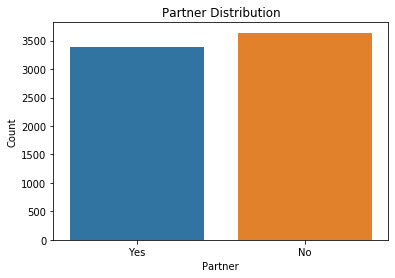

In [41]:
plt.figure(figsize=(6,4))

sns.countplot(data=df, x="Partner")

plt.title("Partner Distribution")
plt.xlabel("Partner")
plt.ylabel("Count")

plt.show()

"The Partner feature is a binary categorical variable indicating whether a customer has a partner (Yes) or not (No). The distribution is fairly balanced, with only a slight majority of customers not having a partner."

In [42]:
# bivariate analysis

pd.crosstab(df["Partner"], df["Churn"])

Churn,No,Yes
Partner,,
No,2439,1200
Yes,2724,669


In [43]:
pd.crosstab(
    df["Partner"],
    df["Churn"],
    normalize="index"
) * 100

Churn,No,Yes
Partner,,
No,67.02,32.98
Yes,80.28,19.72


#### Business Interpretation

Customers who have a partner appear to be less likely to churn.

Possible explanations (these are hypotheses, not proven facts):

Households with partners may have more stable, long-term service needs.
Families may bundle services or stay with a provider longer.
Customers without a partner may be more likely to relocate or switch providers.

"The Partner feature is a balanced binary categorical variable. During bivariate analysis, customers without a partner had a churn rate of about 33%, whereas customers with a partner had a churn rate of about 20%. This suggests that having a partner is associated with a lower likelihood of churn and that Partner is likely to be an informative feature for the model.

In [44]:
# analyzing dependents

df["Dependents"].value_counts()

No     4933
Yes    2099
Name: Dependents, dtype: int64

In [45]:
df["Dependents"].value_counts(normalize= True)*100

No    70.15
Yes   29.85
Name: Dependents, dtype: float64

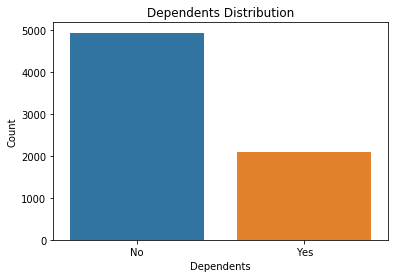

In [47]:
plt.figure(figsize=(6,4))
sns.countplot(data = df, x= df['Dependents'])
plt.title("Dependents Distribution")
plt.xlabel("Dependents")
plt.ylabel("Count")

plt.show()


"Dependents is a binary categorical feature. It is moderately imbalanced, with the majority of customers not having dependents."

In [48]:
pd.crosstab(df["Dependents"], df["Churn"])

Churn,No,Yes
Dependents,,
No,3390,1543
Yes,1773,326


In [49]:
pd.crosstab(
    df["Dependents"],
    df["Churn"],
    normalize="index"
) * 100

Churn,No,Yes
Dependents,,
No,68.72,31.28
Yes,84.47,15.53


#### Business Interpretation

Customers with dependents appear to be much less likely to churn.

Possible reasons (hypotheses only):

Customers with dependents may value service stability.
Families may use multiple telecom services under one account.
Switching providers could be more inconvenient for households.

"Dependents is a moderately imbalanced binary categorical feature. Customers with dependents had a churn rate of about 16%, compared with about 31% for customers without dependents. This suggests that having dependents is associated with a lower likelihood of churn, making it a potentially important predictive featur

In [51]:
# analyzing PhoneService
# Univariate Analysis

df["PhoneService"].value_counts()



Yes    6352
No      680
Name: PhoneService, dtype: int64

In [52]:
df["PhoneService"].value_counts(normalize=True) * 100


Yes   90.33
No     9.67
Name: PhoneService, dtype: float64

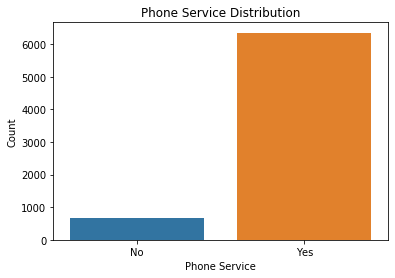

In [53]:
plt.figure(figsize=(6,4))

sns.countplot(data=df, x="PhoneService")

plt.title("Phone Service Distribution")
plt.xlabel("Phone Service")
plt.ylabel("Count")

plt.show()

In [54]:
# Bivariate analysis
pd.crosstab(df["PhoneService"], df["Churn"])

Churn,No,Yes
PhoneService,,
No,510,170
Yes,4653,1699


In [62]:
pd.crosstab(df["PhoneService"], df["Churn"],normalize ="index")*100 

Churn,No,Yes
PhoneService,,
No,75.00,25.00
Yes,73.25,26.75


#### Business Interpretation

Customers with and without phone service have very similar churn behavior.

This suggests that PhoneService alone is not a strong indicator of churn.

PhoneService is a fairly imbalanced binary categorical feature. However, customers with and without phone service have very similar churn rates, indicating that this feature is likely to have low predictive power when considered on its own.

In [65]:
# analyzing MultipleLines
# univariate analysis
df["MultipleLines"].value_counts()



No                  3385
Yes                 2967
No phone service     680
Name: MultipleLines, dtype: int64

In [64]:
df["MultipleLines"].value_counts(normalize=True) * 100

No                 48.14
Yes                42.19
No phone service    9.67
Name: MultipleLines, dtype: float64

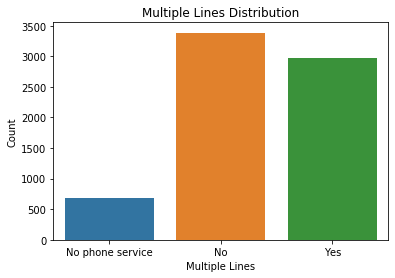

In [66]:
plt.figure(figsize=(6,4))

sns.countplot(data=df, x="MultipleLines")

plt.title("Multiple Lines Distribution")
plt.xlabel("Multiple Lines")
plt.ylabel("Count")

plt.show()

In [67]:
# Bivariate analysis
pd.crosstab(df["MultipleLines"], df["Churn"])

Churn,No,Yes
MultipleLines,,
No,2536,849
No phone service,510,170
Yes,2117,850


In [68]:
pd.crosstab(
    df["MultipleLines"],
    df["Churn"],
    normalize="index"
) * 100

Churn,No,Yes
MultipleLines,,
No,74.92,25.08
No phone service,75.00,25.00
Yes,71.35,28.65


#### Business Interpretation

Customers with multiple phone lines have a slightly higher churn rate, but the difference is fairly small.

Compared with features like:

SeniorCitizen (18% difference)
Partner (13% difference)
Dependents (16% difference)

this feature is much weaker.

MultipleLines is a categorical feature with three categories. Customers with multiple phone lines showed a slightly higher churn rate (around 29%) than customers with one phone line or no phone service (around 25%). The difference is relatively small, so this feature is likely to have moderate to low predictive importance on its own.

In [69]:
# analyzing InternetService

# univariate analysis

df["InternetService"].value_counts()

Fiber optic    3096
DSL            2416
No             1520
Name: InternetService, dtype: int64

In [70]:
df["InternetService"].value_counts(normalize=True) * 100

Fiber optic   44.03
DSL           34.36
No            21.62
Name: InternetService, dtype: float64

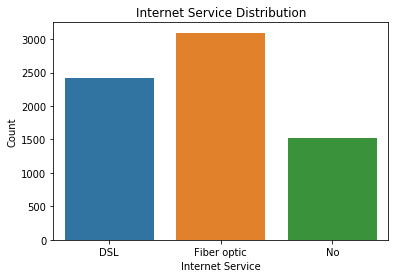

In [71]:
plt.figure(figsize=(6,4))

sns.countplot(data=df, x="InternetService")

plt.title("Internet Service Distribution")
plt.xlabel("Internet Service")
plt.ylabel("Count")

plt.show()

In [72]:
# Bivariate analysis

pd.crosstab(df["InternetService"], df["Churn"])

Churn,No,Yes
InternetService,,
DSL,1957,459
Fiber optic,1799,1297
No,1407,113


In [73]:
pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
) * 100

Churn,No,Yes
InternetService,,
DSL,81.00,19.00
Fiber optic,58.11,41.89
No,92.57,7.43


#### Business Interpretation

This is the first feature where the categories behave very differently.

Customers with Fiber Optic
Highest churn (41.89%).Nearly 2 out of every 5 customers leave.

Customers with DSL
Much lower churn (19%)

Customers with No Internet
Very low churn (7.43%)

Possible explanations include:

Fiber plans may be more expensive, making customers more likely to switch.
Fiber customers may have higher expectations for speed and reliability, so service issues could lead to churn.
Customers without internet service may rely only on basic phone service and have simpler, more stable subscriptions.

"The InternetService feature showed one of the strongest relationships with churn. Customers using Fiber optic had a churn rate of about 42%, compared with 19% for DSL users and only 7% for customers without internet service. This suggests that InternetService is a highly informative feature for predicting churn."

In [74]:
# analyzing OnlineSecurity
# univariate analysis

df["OnlineSecurity"].value_counts()



No                     3497
Yes                    2015
No internet service    1520
Name: OnlineSecurity, dtype: int64

In [75]:
df["OnlineSecurity"].value_counts(normalize=True) * 100

No                    49.73
Yes                   28.65
No internet service   21.62
Name: OnlineSecurity, dtype: float64

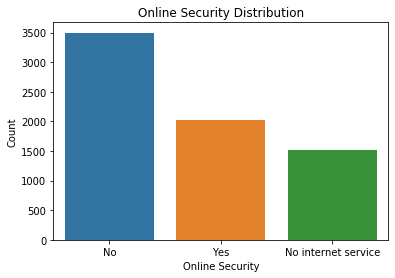

In [76]:
plt.figure(figsize=(6,4))

sns.countplot(data=df, x="OnlineSecurity")

plt.title("Online Security Distribution")
plt.xlabel("Online Security")
plt.ylabel("Count")

plt.show()

Why didn't they simply mark "No internet service" as "No"?

A good answer is:

"Because 'No' and 'No internet service' represent different business situations. A customer with internet who chooses not to buy Online Security is different from a customer who cannot buy it because they don't have internet service. Combining them would lose valuable information."

In [77]:
# Bivariate analysis
pd.crosstab(df["OnlineSecurity"], df["Churn"])

Churn,No,Yes
OnlineSecurity,,
No,2036,1461
No internet service,1407,113
Yes,1720,295


In [78]:
pd.crosstab(
    df["OnlineSecurity"],
    df["Churn"],
    normalize="index"
) * 100

Churn,No,Yes
OnlineSecurity,,
No,58.22,41.78
No internet service,92.57,7.43
Yes,85.36,14.64


#### Business Interpretation

This is much stronger than:

SeniorCitizen (18%)
Partner (13%)
Dependents (16%)

Customers without Online Security are almost 3 times more likely to churn than customers who have it.

Possible reasons:

Customers with Online Security have purchased an additional service, making them more invested in the provider.
They may receive bundled discounts or better overall value.
They may be more satisfied with the company's services.
Customers who don't buy additional services may be more price-sensitive or easier to switch.



What did you learn from the OnlineSecurity feature?

A strong answer would be:

"OnlineSecurity showed a very strong relationship with churn. Customers without Online Security had a churn rate of approximately 42%, whereas customers with Online Security had a churn rate of about 15%. This suggests that OnlineSecurity is one of the strongest predictors of churn in the dataset."

In [80]:
# analyzing OnlineBackup
# univariate analysis

df["OnlineBackup"].value_counts()



No                     3087
Yes                    2425
No internet service    1520
Name: OnlineBackup, dtype: int64

In [81]:

df["OnlineBackup"].value_counts(normalize=True)*100

No                    43.90
Yes                   34.49
No internet service   21.62
Name: OnlineBackup, dtype: float64

In [82]:
# bivariate analysis
pd.crosstab(df["OnlineBackup"], df["Churn"])

Churn,No,Yes
OnlineBackup,,
No,1854,1233
No internet service,1407,113
Yes,1902,523


In [83]:
pd.crosstab(
    df["OnlineBackup"],
    df["Churn"],
    normalize="index"
) * 100

Churn,No,Yes
OnlineBackup,,
No,60.06,39.94
No internet service,92.57,7.43
Yes,78.43,21.57


Most of our strongest features are service adoption features:

InternetService
OnlineSecurity
OnlineBackup

These describe what customers use.

Whereas demographic features:

Gender
SeniorCitizen
Partner

describe who customers are.

In many customer analytics problems, behavioral and service usage features tend to be more predictive than demographic features.

##### Question : Why do you perform EDA before building a machine learning model?

EDA helps us understand the dataset before building a machine learning model. It allows us to understand the distribution of features, identify missing values, detect outliers and inconsistencies, understand relationships between features and the target variable, identify potentially redundant or less informative features, and generate business insights. Performing EDA also helps us decide what preprocessing and feature engineering may be required before model training:

Understand the data – feature types, distributions, and business meaning.
Find data quality issues – missing values, incorrect data types, duplicates, and outliers.
Understand the target variable – whether it is balanced or imbalanced.
Identify relationships – determine which features are associated with the target variable.
Guide preprocessing – decide on encoding, scaling, imputation, and feature engineering.
Generate business insights – explain why customers may be churning, not just predict that they will.

In [86]:
# analyzing DeviceProtection
# univariate
df["DeviceProtection"].value_counts()


No                     3094
Yes                    2418
No internet service    1520
Name: DeviceProtection, dtype: int64

In [85]:

df["DeviceProtection"].value_counts(normalize=True) * 100

No                    44.00
Yes                   34.39
No internet service   21.62
Name: DeviceProtection, dtype: float64

In [87]:
# bivariate analysis
pd.crosstab(
    df["DeviceProtection"],
    df["Churn"],
    normalize="index"
) * 100

Churn,No,Yes
DeviceProtection,,
No,60.86,39.14
No internet service,92.57,7.43
Yes,77.46,22.54


Customers without Device Protection have a much higher churn rate than customers who have it.

Difference:

39.14 − 22.54 = 16.60%

This is a strong relationship.

#### Business Interpretation

Customers purchasing Device Protection appear more engaged with the company's services and are less likely to switch providers.

"DeviceProtection showed a strong association with churn. Customers without Device Protection had substantially higher churn rates than customers who subscribed to the service, making it an important predictive feature."

In [89]:
# analyzing techsupport

# Univariate
df["TechSupport"].value_counts()



No                     3472
Yes                    2040
No internet service    1520
Name: TechSupport, dtype: int64

In [90]:
df["TechSupport"].value_counts(normalize=True) * 100

No                    49.37
Yes                   29.01
No internet service   21.62
Name: TechSupport, dtype: float64

In [91]:
# Bivariate
pd.crosstab(
    df["TechSupport"],
    df["Churn"],
    normalize="index"
) * 100

Churn,No,Yes
TechSupport,,
No,58.35,41.65
No internet service,92.57,7.43
Yes,84.80,15.20


Customers without Tech Support have a much higher churn rate.

Difference:

41.65 − 15.20 = 26.45%

This is a very strong relationship.

#### Business Interpretation

Customers who subscribe to Tech Support appear much more likely to stay with the company. This could be because they receive timely assistance, experience fewer unresolved issues, or perceive greater value from the service.

"TechSupport showed a very strong association with churn. Customers without Tech Support had a churn rate of about 42%, compared with only about 15% for customers with Tech Support, making it one of the most informative predictors in the dataset."

In [92]:
# analyzing StreamingTV and StreamingMovies


In [93]:
# univariate analysis
df["StreamingTV"].value_counts(normalize=True) * 100

No                    39.95
Yes                   38.44
No internet service   21.62
Name: StreamingTV, dtype: float64

In [94]:
# Bivariate analysis
pd.crosstab(
    df["StreamingTV"],
    df["Churn"],
    normalize="index"
) * 100

Churn,No,Yes
StreamingTV,,
No,66.46,33.54
No internet service,92.57,7.43
Yes,69.89,30.11


33.54 − 30.11 = 3.43%

This is quite small.

Unlike TechSupport (26%) or OnlineSecurity (27%), StreamingTV barely separates churn.

#### Business Interpretation

Having StreamingTV does not appear to strongly influence churn.

One possible explanation is that entertainment services alone may not create strong customer loyalty. Customers may subscribe or unsubscribe without that significantly affecting their decision to stay with the telecom provider.

"StreamingTV showed only a small difference in churn rates between subscribers and non-subscribers, suggesting that it is a relatively weak standalone predictor of churn."

Not all add-on services have the same impact on customer retention.

Services that solve problems or provide protection (support, security, backup) appear much more strongly associated with retention than entertainment services like StreamingTV.

In [95]:
# Univariate
df["StreamingMovies"].value_counts()


No                     2781
Yes                    2731
No internet service    1520
Name: StreamingMovies, dtype: int64

In [96]:

df["StreamingMovies"].value_counts(normalize=True) * 100


No                    39.55
Yes                   38.84
No internet service   21.62
Name: StreamingMovies, dtype: float64

In [97]:
# Bivariate
pd.crosstab(
    df["StreamingMovies"],
    df["Churn"],
    normalize="index"
) * 100

Churn,No,Yes
StreamingMovies,,
No,66.27,33.73
No internet service,92.57,7.43
Yes,70.05,29.95


Insight

Difference:

33.73 − 29.95 = 3.78%

Again, a small difference.


#### Business Interpretation

Streaming Movies behaves almost identically to Streaming TV.

Customers with the service churn slightly less, but the difference is too small to consider it a strong standalone predictor.

StreamingMovies showed only a modest association with churn, indicating that entertainment services alone were weaker predictors than support or security-related services.

| Feature            | Importance |
| ------------------ | ---------- |
| 🌟 InternetService | ⭐⭐⭐⭐⭐      |
| 🌟 OnlineSecurity  | ⭐⭐⭐⭐⭐      |
| 🌟 TechSupport     | ⭐⭐⭐⭐⭐      |
| OnlineBackup       | ⭐⭐⭐⭐       |
| SeniorCitizen      | ⭐⭐⭐⭐       |
| DeviceProtection   | ⭐⭐⭐⭐       |
| Dependents         | ⭐⭐⭐        |
| Partner            | ⭐⭐⭐        |
| MultipleLines      | ⭐⭐         |
| StreamingTV        | ⭐⭐         |
| StreamingMovies    | ⭐⭐         |
| PhoneService       | ⭐          |
| Gender             | ⭐          |


In [98]:
# analyzing contract
#univariate analysis

df["Contract"].value_counts()

Month-to-month    3875
Two year          1685
One year          1472
Name: Contract, dtype: int64

In [99]:
# Percentage
df["Contract"].value_counts(normalize=True) * 100

Month-to-month   55.11
Two year         23.96
One year         20.93
Name: Contract, dtype: float64

In [100]:
# Bivariate analysis

pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.72,11.28
Two year,97.15,2.85


Difference:

Month-to-month vs Two-year

42.71 − 2.85 = 39.86%

 Almost 40 percentage points.

#### Business Interpretation

Long-term contracts are strongly associated with lower churn.

Possible reasons:

Customers have contractual commitments.
They may receive discounts for longer contracts.
Switching providers may involve penalties or inconvenience.
Long-term customers may already be satisfied with the service.

Contract type showed one of the strongest relationships with churn. Month-to-month customers had a churn rate of approximately 43%, whereas customers on two-year contracts had a churn rate below 3%. This suggests that contract duration is a highly informative feature for predicting churn.

In [101]:
# analyzing PaperlessBilling
# univariate analysis
df["PaperlessBilling"].value_counts()

Yes    4168
No     2864
Name: PaperlessBilling, dtype: int64

In [102]:
df["PaperlessBilling"].value_counts(normalize=True) * 100


Yes   59.27
No    40.73
Name: PaperlessBilling, dtype: float64

In [103]:
# Bivariate analysis
# Bivariate
pd.crosstab(
    df["PaperlessBilling"],
    df["Churn"],
    normalize="index"
) * 100

Churn,No,Yes
PaperlessBilling,,
No,83.62,16.38
Yes,66.41,33.59


Difference:

33.59 − 16.38 = 17.21%

That's a strong difference.

#### Business Interpretation

Customers using paperless billing have a noticeably higher churn rate.

Possible business hypotheses:

They may be more digitally engaged and compare competitors more easily.
They may prefer convenience and switch providers with less friction.
Paperless billing may also be associated with other characteristics (for example, many month-to-month customers may also use paperless billing).

PaperlessBilling showed a strong association with churn. Customers using paperless billing had approximately double the churn rate of customers receiving paper bills. This suggests that the feature is useful for churn prediction, although the relationship may be influenced by other correlated variables

In [105]:
# analyzing PaymentMethod
# univariate
df["PaymentMethod"].value_counts()


Electronic check             2365
Mailed check                 1604
Bank transfer (automatic)    1542
Credit card (automatic)      1521
Name: PaymentMethod, dtype: int64

In [106]:
df["PaymentMethod"].value_counts(normalize=True) * 100

Electronic check            33.63
Mailed check                22.81
Bank transfer (automatic)   21.93
Credit card (automatic)     21.63
Name: PaymentMethod, dtype: float64

In [107]:
# Bivariate
pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.27,16.73
Credit card (automatic),84.75,15.25
Electronic check,54.71,45.29
Mailed check,80.80,19.20


Electronic check customers have by far the highest churn rate.

Difference from Credit Card:

45.29 − 15.25 = 30.04%

That's a very large difference.

#### Business Interpretation

Customers using automatic payment methods tend to stay much longer.

Possible business hypotheses:

Automatic payments reduce payment friction.
Customers who enable automatic payments may be more committed.
Electronic check users may be more price-sensitive or less committed.
Automatic payments may often be associated with longer contracts.

PaymentMethod showed a strong association with churn. Customers using Electronic Check had the highest churn rate (about 45%), whereas customers using automatic payment methods had much lower churn rates (around 15–17%). This indicates that PaymentMethod is a valuable predictive feature.

| Rank                | Feature         | Importance |
| ------------------- | --------------- | ---------- |
| 🥇 Contract         | ⭐⭐⭐⭐⭐           |            |
| 🥇 InternetService  | ⭐⭐⭐⭐⭐           |            |
| 🥇 OnlineSecurity   | ⭐⭐⭐⭐⭐           |            |
| 🥇 TechSupport      | ⭐⭐⭐⭐⭐           |            |
| 🥇 PaymentMethod    | ⭐⭐⭐⭐⭐           |            |
| 🥈 OnlineBackup     | ⭐⭐⭐⭐            |            |
| 🥈 SeniorCitizen    | ⭐⭐⭐⭐            |            |
| 🥈 DeviceProtection | ⭐⭐⭐⭐            |            |
| 🥈 PaperlessBilling | ⭐⭐⭐⭐            |            |
| 🥉 Dependents       | ⭐⭐⭐             |            |
| 11                  | Partner         | ⭐⭐⭐        |
| 12                  | StreamingTV     | ⭐⭐         |
| 13                  | StreamingMovies | ⭐⭐         |
| 14                  | MultipleLines   | ⭐⭐         |
| 15                  | PhoneService    | ⭐          |
| 16                  | Gender          | ⭐          |


### Numerical Features

In [109]:
# analyzing tenure

# Summary statistics
df["tenure"].describe()


count   7032.00
mean      32.42
std       24.55
min        1.00
25%        9.00
50%       29.00
75%       55.00
max       72.00
Name: tenure, dtype: float64

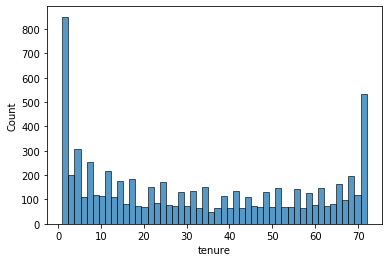

In [113]:
sns.histplot(df["tenure"], bins=50)

/opt/anaconda3/lib/python3.7/site-packages/matplotlib/cbook/__init__.py:1402: FutureWarning: Support for multi-dimensional indexing (e.g. `obj[:, None]`) is deprecated and will be removed in a future version.  Convert to a numpy array before indexing instead.
  x[:, None]
/opt/anaconda3/lib/python3.7/site-packages/matplotlib/axes/_base.py:276: FutureWarning: Support for multi-dimensional indexing (e.g. `obj[:, None]`) is deprecated and will be removed in a future version.  Convert to a numpy array before indexing instead.
  x = x[:, np.newaxis]
/opt/anaconda3/lib/python3.7/site-packages/matplotlib/axes/_base.py:278: FutureWarning: Support for multi-dimensional indexing (e.g. `obj[:, None]`) is deprecated and will be removed in a future version.  Convert to a numpy array before indexing instead.
  y = y[:, np.newaxis]


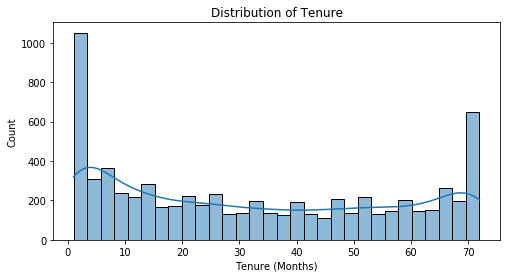

In [110]:

# Histogram
plt.figure(figsize=(8,4))
sns.histplot(df["tenure"], bins=30, kde=True)

plt.title("Distribution of Tenure")
plt.xlabel("Tenure (Months)")
plt.show()

Why do we use a histogram instead of value_counts() for tenure?

A strong answer is:

"Because tenure is a continuous numerical variable with many unique values. value_counts() would list every distinct value, making it difficult to understand the overall distribution. A histogram groups the values into intervals (bins), allowing us to visualize where observations are concentrated and identify the shape of the distribution."

⭐ This is an important distinction:

Categorical features → value_counts(), countplot()
Numerical features → describe(), histogram, boxplot

##### What do you observe?


"The tenure distribution appears bimodal, with one peak representing new customers and another representing long-term customers. There are relatively fewer customers with medium tenure. This suggests the company has both recently acquired customers and a stable base of long-term customers

A histogram shows:

How tenure is distributed overall.

A boxplot compares:

The distribution of tenure between two groups:

Customers who stayed (No)
Customers who churned (Yes)

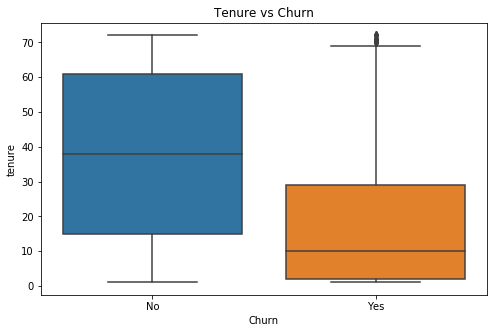

In [114]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="Churn",
    y="tenure"
)

plt.title("Tenure vs Churn")

plt.show()

##### Observations:

The median tenure for customers who stayed is much higher than for customers who churned.
That means:
Customers who churn generally have much shorter tenure.


The blue box (No) is much higher than the orange box (Yes).
That means the middle 50% of customers who stayed have much higher tenure than the middle 50% of customers who churned.
Again, this suggests:
Long-term customers are much more likely to stay.


The churned customers have a few outliers (those dots near the top).
These represent customers who stayed with the company for a long time but still eventually churned.
So although most churn happens among newer customers, a few long-term customers also leave.

#### Business Interpretation

This is one of the strongest business insights we've found.

Customers who have been with the company for many months tend to remain loyal.

Newer customers are much more likely to leave.

This suggests that the early months of the customer journey are critical for retention.

A histogram shows the distribution of a single variable. A box plot is more suitable here because it allows us to compare the distributions of tenure across two groups (Churn = Yes and Churn = No) using the median, spread, and potential outliers.

In [115]:
df.groupby("Churn")["tenure"].describe()

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5163.00,37.65,24.08,1.00,15.00,38.00,61.00,72.00
Yes,1869.00,17.98,19.53,1.00,2.00,10.00,29.00,72.00


### Note

For categorical features, we compared:

value_counts()

crosstab()

For numerical features, we compare:

Mean
Median
Quartiles (25%, 75%)
Distribution (Histogram)
Spread (Box Plot)

This is the standard workflow you'll use for almost every numerical feature in EDA.

In [116]:
# analyzing MonthlyCharges

#univariate analysis

df["MonthlyCharges"].describe()

count   7032.00
mean      64.80
std       30.09
min       18.25
25%       35.59
50%       70.35
75%       89.86
max      118.75
Name: MonthlyCharges, dtype: float64

/opt/anaconda3/lib/python3.7/site-packages/matplotlib/cbook/__init__.py:1402: FutureWarning: Support for multi-dimensional indexing (e.g. `obj[:, None]`) is deprecated and will be removed in a future version.  Convert to a numpy array before indexing instead.
  x[:, None]
/opt/anaconda3/lib/python3.7/site-packages/matplotlib/axes/_base.py:276: FutureWarning: Support for multi-dimensional indexing (e.g. `obj[:, None]`) is deprecated and will be removed in a future version.  Convert to a numpy array before indexing instead.
  x = x[:, np.newaxis]
/opt/anaconda3/lib/python3.7/site-packages/matplotlib/axes/_base.py:278: FutureWarning: Support for multi-dimensional indexing (e.g. `obj[:, None]`) is deprecated and will be removed in a future version.  Convert to a numpy array before indexing instead.
  y = y[:, np.newaxis]


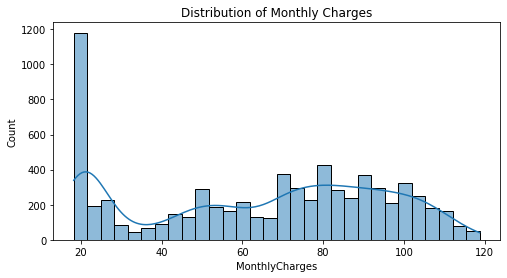

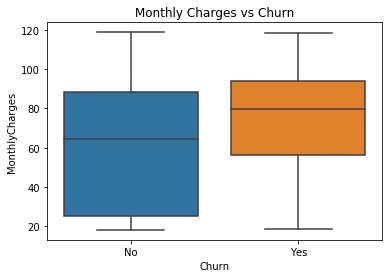

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5163.00,61.31,31.09,18.25,25.10,64.45,88.47,118.75
Yes,1869.00,74.44,24.67,18.85,56.15,79.65,94.20,118.35


In [117]:
plt.figure(figsize=(8,4))
sns.histplot(df["MonthlyCharges"], bins=30, kde=True)
plt.title("Distribution of Monthly Charges")
plt.show()

sns.boxplot(data=df, x="Churn", y="MonthlyCharges")
plt.title("Monthly Charges vs Churn")
plt.show()

df.groupby("Churn")["MonthlyCharges"].describe()

##### Distribution

From the histogram :

Charges range roughly from ₹18 to ₹119 (or equivalent units).
The distribution is usually spread across the range, not concentrated in one small interval.

#### Observations

The orange box (Churn = Yes) is clearly higher than the blue box.
That means:
Customers who churn generally have higher monthly charges.

Average monthly bill:
Stayed → 61.31 ,Churned → 74.44
Difference:≈ 13 units


Median:
Stayed → 64.45
Churned → 79.65
This is even more convincing because the median is less influenced by extreme values.

overall distribution for churned customers is shifted toward higher monthly charges.

#### Business Interpretation

Customers paying higher monthly charges are more likely to churn.

Possible business explanations:

Higher bills may increase price sensitivity.
Customers paying more may compare competitors more frequently.
Customers with expensive plans may expect a higher level of service and may leave if those expectations aren't met.

In [118]:
# analyzing Totalcharges
# univariate
df["TotalCharges"].describe()


count   7032.00
mean    2283.30
std     2266.77
min       18.80
25%      401.45
50%     1397.47
75%     3794.74
max     8684.80
Name: TotalCharges, dtype: float64

/opt/anaconda3/lib/python3.7/site-packages/matplotlib/cbook/__init__.py:1402: FutureWarning: Support for multi-dimensional indexing (e.g. `obj[:, None]`) is deprecated and will be removed in a future version.  Convert to a numpy array before indexing instead.
  x[:, None]
/opt/anaconda3/lib/python3.7/site-packages/matplotlib/axes/_base.py:276: FutureWarning: Support for multi-dimensional indexing (e.g. `obj[:, None]`) is deprecated and will be removed in a future version.  Convert to a numpy array before indexing instead.
  x = x[:, np.newaxis]
/opt/anaconda3/lib/python3.7/site-packages/matplotlib/axes/_base.py:278: FutureWarning: Support for multi-dimensional indexing (e.g. `obj[:, None]`) is deprecated and will be removed in a future version.  Convert to a numpy array before indexing instead.
  y = y[:, np.newaxis]


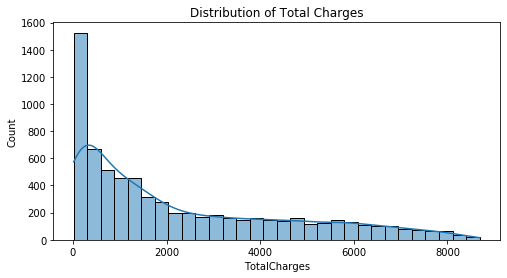

In [119]:

plt.figure(figsize=(8,4))
sns.histplot(df["TotalCharges"], bins=30, kde=True)
plt.title("Distribution of Total Charges")
plt.show()


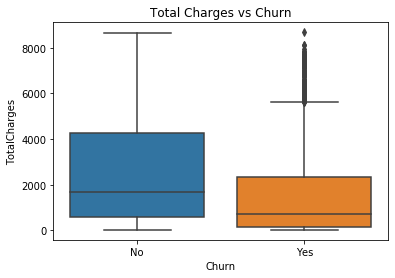

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5163.00,2555.34,2329.46,18.80,577.83,1683.60,4264.12,8672.45
Yes,1869.00,1531.80,1890.82,18.85,134.50,703.55,2331.30,8684.80


In [120]:
# Bivariate analysis
sns.boxplot(data=df, x="Churn", y="TotalCharges")
plt.title("Total Charges vs Churn")
plt.show()

df.groupby("Churn")["TotalCharges"].describe()


TotalCharges = Total amount the customer has paid since joining the company.
It depends on:
MonthlyCharges
Tenure


Distribution (Histogram)
Huge concentration near low TotalCharges.
Long tail extending toward very high values.
This is a right-skewed distribution.


Box Plot
Notice something.The blue box (Stayed)is higher than the orange box (Churn).
Immediately this tells us Customers who stayed generally have higher TotalCharges.

##### Insight

Average TotalCharges
Stayed:₹2555
Churned:₹1532

Difference:
More than ₹1000.

Median
Stayed:₹1684
Churned:₹704

Again,

customers who stayed have paid much more over their lifetime.

#### Business Interpretation

Customers with high TotalCharges are usually

long-term customers,
loyal customers,
customers retained for years.

Therefore

higher TotalCharges

is associated with

lower churn.

Although customers who churn have higher monthly charges, customers who stay have significantly higher TotalCharges because they remain with the company for much longer. This indicates that the influence of tenure outweighs the influence of monthly charges when considering TotalCharges

Why don't we use Label Encoding for nominal variables?


"Because Label Encoding introduces an artificial order between categories. For nominal features like colour or internet service, there is no meaningful ranking, so One-Hot Encoding is preferred to avoid misleading the model."

##### ordinal variables should use Label Encoding
##### nominal variables should use one hot Encoding

### let's start preprocessing

In [121]:
# Separate features and target

X = df.drop(columns='Churn')
y = df['Churn']

print("Shape of X:", X.shape)
print("Shape of y:", y.shape)

Shape of X: (7032, 20)
Shape of y: (7032,)


In [122]:
from sklearn.preprocessing import LabelEncoder

In [123]:
# encode the target variable
label_encoder = LabelEncoder()
y= label_encoder.fit_transform(y)
print(y[:10])

[0 0 1 0 1 1 0 0 1 0]


In [124]:
print(label_encoder.classes_) # These are the original categories I learned from

['No' 'Yes']


In [125]:
X.dtypes

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
dtype: object

## Preprocessing plan

| Feature Type                                                                  | What we'll do    |
| ----------------------------------------------------------------------------- | ---------------- |
| Numerical (`tenure`, `MonthlyCharges`, `TotalCharges`)                        | Keep as they are |
| Binary categorical already encoded (`SeniorCitizen`)                          | Keep as it is    |
| Binary text columns (`Partner`, `Dependents`, etc.)                           | Convert to 0/1   |
| Multi-category columns (`InternetService`, `Contract`, `PaymentMethod`, etc.) | One-Hot Encode   |


## Rule of Thumb

| Number of Categories                      | Preferred Encoding                                  |
| ----------------------------------------- | --------------------------------------------------- |
| 2 (Yes/No, Male/Female)                   | Label Encoding (Binary Encoding)                    |
| More than 2 without any order             | One-Hot Encoding                                    |
| Ordered categories (Small, Medium, Large) | Ordinal/Label Encoding (depending on the situation) |


In [127]:
X.select_dtypes(include='object').nunique()

customerID          7032
gender                 2
Partner                2
Dependents             2
PhoneService           2
MultipleLines          3
InternetService        3
OnlineSecurity         3
OnlineBackup           3
DeviceProtection       3
TechSupport            3
StreamingTV            3
StreamingMovies        3
Contract               3
PaperlessBilling       2
PaymentMethod          4
dtype: int64

In [128]:
# Drop customerID

X = X.drop(columns='customerID')

print(X.shape)

(7032, 19)


In [129]:
# Find binary categorical columns

binary_cols = [col for col in X.select_dtypes(include='object').columns
               if X[col].nunique() == 2]

binary_cols

['gender', 'Partner', 'Dependents', 'PhoneService', 'PaperlessBilling']

In [131]:
#Encode the Binary Columns

le = LabelEncoder()
for col in binary_cols:
    X[col] = le.fit_transform(X[col])
    
X[binary_cols].head()    
    

,gender,Partner,Dependents,PhoneService,PaperlessBilling
0,0,1,0,0,1
1,1,0,0,1,0
2,1,0,0,1,1
3,1,0,0,0,0
4,0,0,0,1,1


In [132]:
# Find categorical columns with more than 2 unique values

multi_cols = [col for col in X.select_dtypes(include='object').columns
              if X[col].nunique() > 2]

multi_cols

['MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaymentMethod']

Why is it called One-Hot Encoding?

"Because each category is represented by a separate binary column, and for every observation, exactly one of those columns is 'hot' (1) while all the others are 0."

In [133]:
# Apply One-Hot Encoding

X = pd.get_dummies(
    X,
    columns=multi_cols,
    drop_first=True,
    dtype=int
)

print(X.shape)

(7032, 30)


In [134]:
X.columns

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'PaperlessBilling', 'MonthlyCharges', 'TotalCharges',
       'MultipleLines_No phone service', 'MultipleLines_Yes',
       'InternetService_Fiber optic', 'InternetService_No',
       'OnlineSecurity_No internet service', 'OnlineSecurity_Yes',
       'OnlineBackup_No internet service', 'OnlineBackup_Yes',
       'DeviceProtection_No internet service', 'DeviceProtection_Yes',
       'TechSupport_No internet service', 'TechSupport_Yes',
       'StreamingTV_No internet service', 'StreamingTV_Yes',
       'StreamingMovies_No internet service', 'StreamingMovies_Yes',
       'Contract_One year', 'Contract_Two year',
       'PaymentMethod_Credit card (automatic)',
       'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check'],
      dtype='object')

Why do we perform a train-test split?

To evaluate how well the model generalizes to unseen data. If we train and test on the same dataset, the model may memorize the training examples, leading to overly optimistic performance. A separate test set provides an unbiased estimate of real-world performance.

In [135]:
# train-test split

from sklearn.model_selection import train_test_split

# Split the data

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [136]:
print("X_train shape:", X_train.shape)
print("X_test shape :", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape :", y_test.shape)

X_train shape: (5625, 30)
X_test shape : (1407, 30)
y_train shape: (5625,)
y_test shape : (1407,)


#### Prevention of data leakage

The correct approach

Always split first.

Train-Test Split
        ↓
Fit preprocessing on X_train
        ↓
Transform X_train
        ↓
Transform X_test

What is data leakage?

"Data leakage occurs when information from the test set is used during training. This leads to overly optimistic model performance because the model has indirectly seen information it shouldn't have had access to."

### Running the model

Import XGBoost, 
Create the model ,
Train it using .fit() ,
Make predictions ,
Evaluate performance

In [138]:
# import the model
import xgboost
from xgboost import XGBClassifier

In [139]:


# Create the XGBoost model

xgb_model = XGBClassifier(
    random_state=42,
    eval_metric='logloss'
)

In [140]:
# Train the model

xgb_model.fit(X_train, y_train)

XGBClassifier(base_score=0.5, booster='gbtree', callbacks=None,
              colsample_bylevel=1, colsample_bynode=1, colsample_bytree=1,
              early_stopping_rounds=None, enable_categorical=False,
              eval_metric='logloss', gamma=0, gpu_id=-1,
              grow_policy='depthwise', importance_type=None,
              interaction_constraints='', learning_rate=0.300000012,
              max_bin=256, max_cat_to_onehot=4, max_delta_step=0, max_depth=6,
              max_leaves=0, min_child_weight=1, missing=nan,
              monotone_constraints='()', n_estimators=100, n_jobs=0,
              num_parallel_tree=1, predictor='auto', random_state=42,
              reg_alpha=0, reg_lambda=1, ...)

In [141]:
# Predict on the test set

y_pred = xgb_model.predict(X_test)

print(y_pred[:10])

[0 0 1 0 0 1 0 1 0 0]


In [142]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[913 120]
 [191 183]]


Out of 1,407 unseen customers, the model correctly identified 913 customers who stayed and 183 customers who churned. It incorrectly flagged 120 loyal customers as likely to churn and missed 191 customers who actually churned.

In most churn prediction problems:

False Negatives are more costly than False Positives.

In [143]:
accuracy = (913 + 183) / 1407
print(accuracy)

0.7789623312011372


Out of every 100 unseen customers, the model correctly predicts about 78 of them.

Is accuracy always a good metric?"


"No. Accuracy can be misleading for imbalanced datasets. For problems like fraud detection, disease prediction, or customer churn, metrics such as Precision, Recall, F1-score, and ROC-AUC provide a much better evaluation."

###### Precision is Correct Positive Predictions ÷ All Positive Predictions
###### Precision looks at all predicted churners.
###### Recall looks at all actual churners.

In [144]:
precision = 183 / (183 + 120)
print(precision)

0.6039603960396039


What does a Precision of 60% mean?


"It means that when the model predicts a customer will churn, it is correct about 60% of the time. The remaining 40% are false positives."

In [145]:
recall = 183 / (183 + 191)
print(recall)

0.4893048128342246


| Metric    | Your Value | Meaning                                        |
| --------- | ---------: | ---------------------------------------------- |
| Accuracy  |  **77.9%** | Overall correct predictions                    |
| Precision |  **60.4%** | Of predicted churners, 60.4% actually churned  |
| Recall    |  **48.9%** | Of actual churners, only 48.9% were identified |


Precision (60.4%) is higher than your Recall (48.9%).
It means your model is fairly cautious.
When it predicts "This customer will churn," it's right quite often (60%).
But it's also missing many customers who actually churn.
In other words:
The model is conservative—it avoids making too many churn predictions, but in doing so, it fails to catch many real churners.

##### Would you prefer higher Precision or higher Recall for customer churn prediction?

"Usually, Recall is more important because missing a customer who is about to churn (False Negative) can result in losing future revenue. However, the ideal balance depends on the cost of retention campaigns and the business objective."

Now, 
Which model is better?

One with 90% Precision and 30% Recall?
Or one with 70% Precision and 70% Recall?
Neither metric alone tells the full story.
That's why we use F1-score.

In [146]:
# Calculate F1 score
from sklearn.metrics import f1_score

f1 = f1_score(y_test, y_pred)
print(f1)

0.5406203840472673


##### Lets put everything together:

| Metric    |     Value | Meaning                                                          |
| --------- | --------: | ---------------------------------------------------------------- |
| Accuracy  | **77.9%** | Overall predictions that were correct                            |
| Precision | **60.4%** | When the model predicted churn, it was correct 60.4% of the time |
| Recall    | **48.9%** | The model found only 48.9% of actual churners                    |
| F1-score  | **54.1%** | Overall balance between Precision and Recall                     |


The F1-score lies between Precision and Recall, just as we expected.

What does an F1-score of 54.1% mean?

It means your model has a moderate balance between:
Avoiding false alarms (Precision)
Catching actual churners (Recall)

The model isn't terrible, but it also isn't catching enough customers who actually churn.

###### Why do we use F1-score instead of Accuracy?

"F1-score combines Precision and Recall into a single metric. It is especially useful for imbalanced datasets where Accuracy can be misleading. It helps evaluate whether the model is both identifying positive cases effectively and avoiding too many false positives."

In [147]:
# professional way

from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.83      0.88      0.85      1033
           1       0.60      0.49      0.54       374

    accuracy                           0.78      1407
   macro avg       0.72      0.69      0.70      1407
weighted avg       0.77      0.78      0.77      1407



What is the difference between Macro Average and Weighted Average?

Macro Average gives equal importance to every class, regardless of how many samples each class has. Weighted Average takes the number of samples in each class into account, so larger classes have a greater influence on the final score.

### Hyperparameter Tuning

In [148]:
from sklearn.model_selection import GridSearchCV

In [150]:
# create the parameter grid

param_grid = {
    'n_estimators': [100, 200],   #number of trees
    'max_depth': [3, 5, 7],      #more complex trees, more back to back questions
    'learning_rate': [0.01, 0.1] #step
}

In [151]:
# Create the GridSearchCV Object

grid_search = GridSearchCV(
    estimator=xgb_model,
    param_grid=param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)